In [86]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics import tsaplots
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import het_arch, acorr_ljungbox
from arch import arch_model

In [87]:
df = pd.read_parquet("../DATOS/TRANSFORMADOS/df_diario.parquet")

In [88]:
df

Ticker,AAPL,AMGN,AXP,BA,CAT,CRM,CSCO,CVX,DIS,DOW,...,KO,MCD,MMM,MRK,MSFT,NKE,PG,TRV,UNH,V
Atributo,open,open,open,open,open,open,open,open,open,open,...,adj close,adj close,adj close,adj close,adj close,adj close,adj close,adj close,adj close,adj close
2018-06-06,45.803260,147.060853,90.831614,348.858528,131.109462,133.374320,35.413420,90.796595,96.121399,NaN,...,33.519558,133.685410,128.639145,45.619328,94.516289,66.114006,59.448215,107.609100,215.247879,128.590698
2018-06-07,45.927449,148.240513,92.139591,358.040544,134.061884,134.585641,35.801869,91.843793,97.898584,NaN,...,33.504131,139.530716,129.402634,45.663540,93.031555,66.122833,60.575588,109.097145,215.533554,126.288330
2018-06-08,45.176401,148.579864,92.003343,354.325406,133.276850,130.763026,35.219198,93.746452,98.071492,NaN,...,33.897491,139.061371,130.361816,46.098148,93.723198,66.246681,61.710991,110.400223,217.005142,127.137596
2018-06-11,45.262742,148.781859,91.903427,357.078069,132.355285,132.927524,35.300123,93.488335,99.839069,NaN,...,34.036316,137.069077,129.434250,45.913998,93.188309,65.972466,61.990837,109.710854,219.688721,126.354439
2018-06-12,45.272204,148.886901,92.194088,357.309054,133.703498,133.999842,35.348680,94.129931,100.607582,NaN,...,34.252262,137.266632,129.308029,45.995026,93.428078,65.707161,61.758949,108.937386,219.515579,127.250839
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-06-02,200.279999,285.640015,292.350006,210.979996,346.470001,263.109985,62.730000,138.490005,112.680000,27.660000,...,69.110367,303.118408,143.085358,72.623184,457.448090,59.296558,160.815430,269.972046,292.876587,361.784912
2025-06-03,201.350006,285.519989,295.200012,212.000000,346.000000,262.000000,63.799999,137.649994,112.730003,27.200001,...,68.304070,302.837311,144.776199,73.470856,458.438263,60.067020,159.924057,269.708252,289.512634,362.319702
2025-06-04,202.910004,290.190002,297.809998,214.770004,350.299988,264.190002,64.660004,139.419998,113.860001,27.850000,...,68.505646,302.042389,143.486099,74.547112,459.329468,60.452251,159.061401,265.595276,288.705292,364.438995


In [89]:
df_filtrado = df[['CAT', 'GS', 'KO']].xs("close",level=1,axis=1)
df_filtrado

Ticker,CAT,GS,KO
2018-06-06,133.549899,197.883033,34.921078
2018-06-07,133.362172,198.922596,34.905008
2018-06-08,132.534484,198.871472,35.314806
2018-06-11,133.392044,199.885470,35.459440
2018-06-12,135.358899,198.496548,35.684425
...,...,...,...
2025-06-02,344.670013,598.719971,72.000000
2025-06-03,349.399994,603.830017,71.160004
2025-06-04,349.329987,599.210022,71.370003
2025-06-05,348.959991,605.880005,70.910004


In [90]:
CAT = df_filtrado["CAT"]
GS = df_filtrado["GS"]
KO = df_filtrado["KO"]

<Axes: >

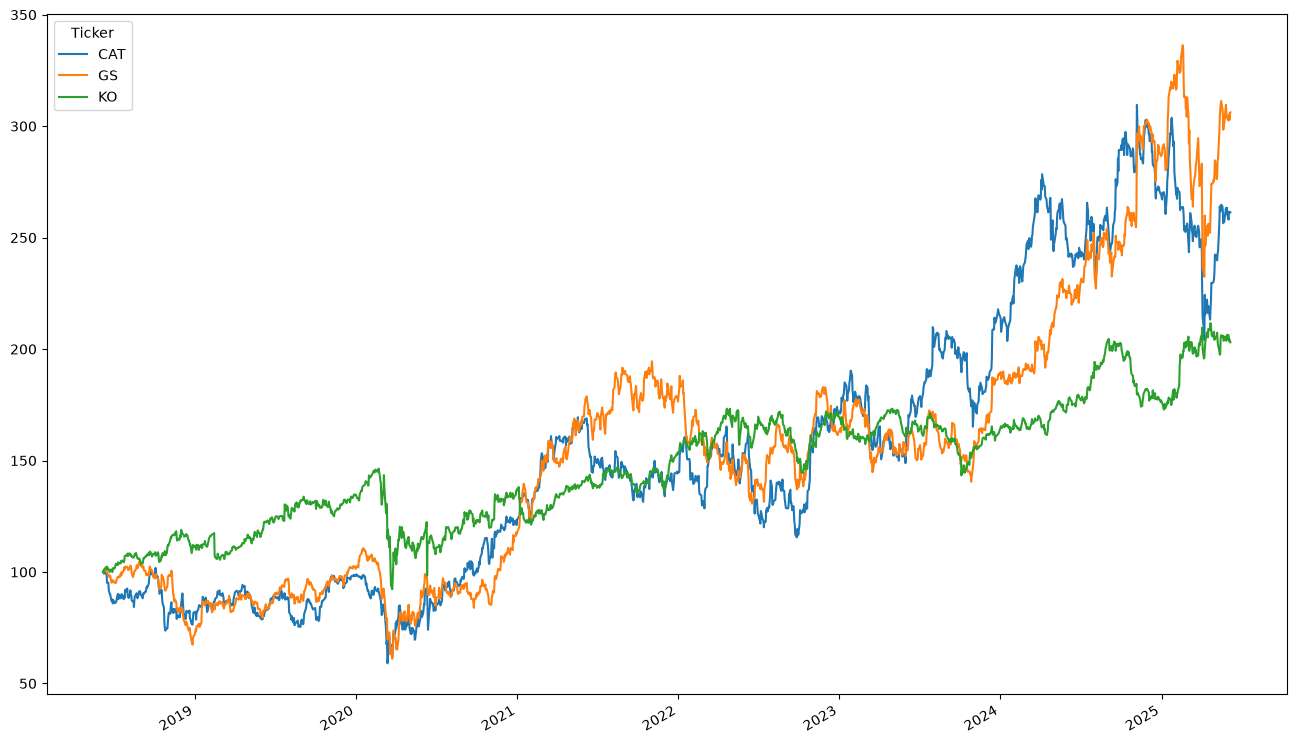

In [91]:
precios_norm = (df_filtrado / df_filtrado.iloc[0]) * 100

precios_norm.plot(figsize=(16,10))

#### Pasos a seguir

Analizar los componentes de la serie y tratarla como es debida para convertirla en estacionaria.

Si estacionalidad -> descomposición estacional
Si no estacionalidad -> tratar tendencia

Si tras tratar la serie existe heterocedasticidad -> Modelizar la volatilidad (ARCH o GARCH)

En caso de modelizar la volatilidad, se han mirado las autocorrelaciones y autocorrelaciones parciales sobre los rendimientos del activo al cuadrado. Sobre los resultados mostrados en las gráficas ACF y PACF se han decidido los parámetros con los que tratar de ajustar los ARCH y GARCH.


Para admitir un modelo, debe de cumplir con los siguientes puntos:
- Parámetros de modelo significativos
- El residuo post-modelo es homocedástico (ya no queda volatilidad)

In [92]:
def test_estacionariedad_y_het(series, lags=None):
    series = series.dropna()
    
    resultados = {}
    
    # 1. ADF
    adf_stat, adf_p, _, _, _, _ = adfuller(series, autolag='AIC')
    resultados['ADF'] = {
        'Estadístico': adf_stat,
        'p-value': adf_p,
        'Estacionariedad (0.05)': adf_p < 0.05
    }
    
    # 2. KPSS 
    kpss_stat, kpss_p, _, _ = kpss(series, regression='c', nlags='auto')
    resultados['KPSS'] = {
        'Estadístico': kpss_stat,
        'p-value': kpss_p,
        'Estacionariedad (0.05)': kpss_p > 0.05
    }
    
    # 3. ARCH
    arch_stat, arch_p, _, _ = het_arch(series, nlags=lags)
    resultados['ARCH_Heteroskedasticity'] = {
        'Estadístico': arch_stat,
        'p-value': arch_p,
        'Estacionariedad (0.05)': arch_p < 0.05
    }
    
    return pd.DataFrame(resultados).T

In [114]:
def evaluate_volatility_models(returns, max_arch_p=4):
    results = []
    
    for p in range(1, max_arch_p + 1):
        model = arch_model(returns, vol='ARCH', p=p, rescale=False)
        res = model.fit(disp='off')
        
        pvals = res.pvalues
        all_sig = all(pvals < 0.05)
        pvals_str = ", ".join([f"{idx}: {val:.4f}" for idx, val in pvals.items()])
        
        std_resid = res.std_resid.dropna()
        _, arch_lm_pval, _, _ = het_arch(std_resid, nlags=5)
        lm_passed = arch_lm_pval > 0.05
        
        results.append({
            'Modelo': f'ARCH({p})',
            'Todos los Parametros Signifiactivos (<0.05)': all_sig,
            'ARCH-LM P-value': round(arch_lm_pval, 4),
            'Homocedastica (>0.05)': lm_passed,
            'P-values de los Parametros del Modelo': pvals_str
        })
        
    garch_configs = [(1, 1), (1, 2), (2, 1), (2, 2)]
    for p, q in garch_configs:
        model = arch_model(returns, vol='Garch', p=p, q=q, rescale=False, dist="normal", mean="Constant")
        res = model.fit(disp='off')
        
        pvals = res.pvalues
        all_sig = all(pvals < 0.05)
        pvals_str = ", ".join([f"{idx}: {val:.4f}" for idx, val in pvals.items()])
        
        std_resid = res.std_resid.dropna()
        _, arch_lm_pval, _, _ = het_arch(std_resid, nlags=5)
        lm_passed = arch_lm_pval > 0.05
        
        results.append({
            'Modelo': f'GARCH({p},{q})',
            'Todos los Parametros Significativos (<0.05)': all_sig,
            'ARCH-LM P-value': round(arch_lm_pval, 4),
            'Homocedastica (>0.05)': lm_passed,
            'P-values de los Parametros del Modelo': pvals_str
        })
        
    return pd.DataFrame(results)

## Tratamiento de las series temporales

### CAT (Caterpillar)

<Axes: >

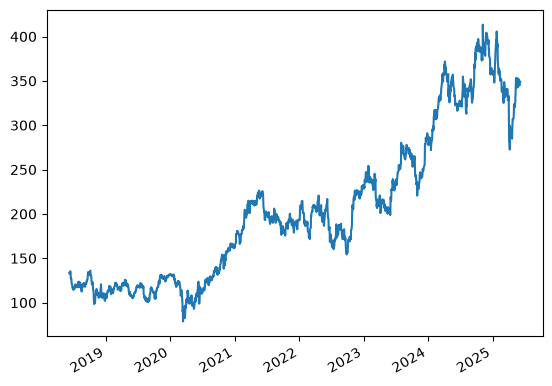

In [94]:
CAT.plot()

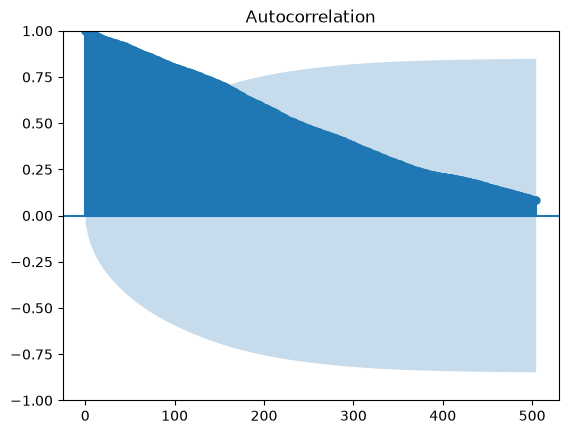

In [95]:
tsaplots.plot_acf(CAT, lags=504);

Al no descubrir ninguna estacionalidad, quitaremos solamente la tendencia y observaremos la homocedasticidad. Al tratarse de una serie financiera, y al poder diferenciar la serie para restarle la tendencia; se decide trabajar sobre los retornos. Los retornos o rentabilidades son un resultado similar a la diferenciación, además de ser el estándar del sector para tratar las series temporales, no sobre los precios absolutos.

In [96]:
CAT_r = CAT.pct_change().dropna()*100

<Axes: >

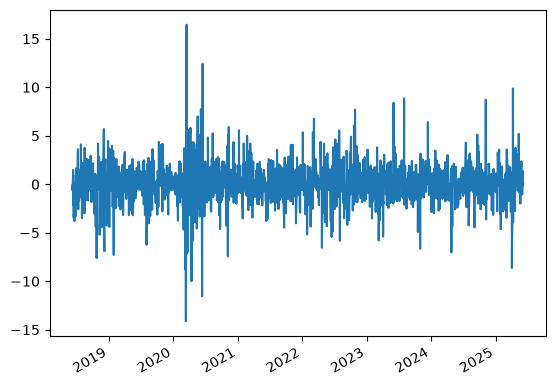

In [97]:
CAT_r.plot()

In [99]:
test_estacionariedad_y_het(CAT_r)

C:\Users\Markel\AppData\Local\Temp\ipykernel_19576\3844326302.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, adf_p, _, _, _, _ = adfuller(series, autolag='AIC')
C:\Users\Markel\AppData\Local\Temp\ipykernel_19576\3844326302.py:15: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_stat, kpss_p, _, _ = kpss(series, regression='c', nlags='auto')
C:\Users\Markel\AppData\Local\Temp\ipykernel_19576\3844326302.py:15: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lag

,Estadístico,p-value,Estacionariedad (0.05)
ADF,-15.392905,0.0,True
KPSS,0.060526,0.1,True
ARCH_Heteroskedasticity,234.741924,0.0,True


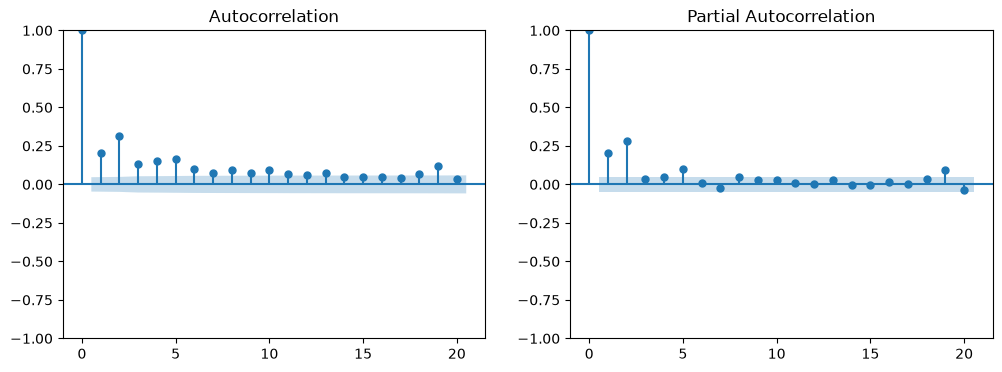

In [100]:
CAT_sq = CAT_r ** 2

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
tsaplots.plot_acf(CAT_sq, lags=20, ax=ax[0])
tsaplots.plot_pacf(CAT_sq, lags=20, ax=ax[1])
plt.show()

In [101]:
tabla_resumen = evaluate_volatility_models(CAT_r, max_arch_p=2)
print(tabla_resumen.to_string(index=False))

c:\BDATA\BDATAIII\CasosPrácticosIII\26-27_3_R9_EQUIPO_MORADO\.venv\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(
c:\BDATA\BDATAIII\CasosPrácticosIII\26-27_3_R9_EQUIPO_MORADO\.venv\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


     Model  All Params Significant (<0.05)  ARCH-LM P-value  ARCH-LM Passed (>0.05)                                                                              Parameter P-values
   ARCH(1)                           False           0.0000                   False                                                     mu: 0.5910, omega: 0.0000, alpha[1]: 0.0045
   ARCH(2)                           False           0.0000                   False                                   mu: 0.1569, omega: 0.0000, alpha[1]: 0.0009, alpha[2]: 0.0012
GARCH(1,1)                           False           0.5888                    True                                    mu: 0.0983, omega: 0.0053, alpha[1]: 0.0008, beta[1]: 0.0000
GARCH(1,2)                           False           0.5813                    True                   mu: 0.1040, omega: 0.0060, alpha[1]: 0.0016, beta[1]: 0.0176, beta[2]: 0.6621
GARCH(2,1)                           False           0.5889                    True                 

c:\BDATA\BDATAIII\CasosPrácticosIII\26-27_3_R9_EQUIPO_MORADO\.venv\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(
c:\BDATA\BDATAIII\CasosPrácticosIII\26-27_3_R9_EQUIPO_MORADO\.venv\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(
c:\BDATA\BDA

### GS (Goldman Sachs)

<Axes: >

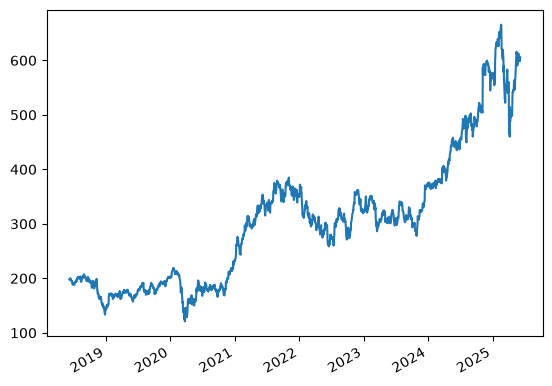

In [102]:
GS.plot()

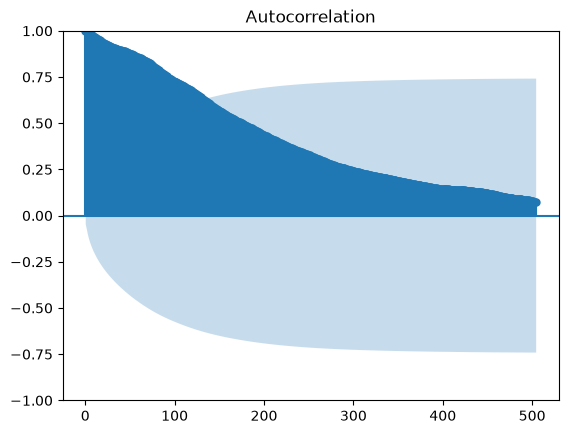

In [103]:
tsaplots.plot_acf(GS, lags=504);

Al no descubrir ninguna estacionalidad, quitaremos solamente la tendencia y observaremos la homocedasticidad. Al tratarse de una serie financiera, y al poder diferenciar la serie para restarle la tendencia; se decide trabajar sobre los retornos. Los retornos o rentabilidades son un resultado similar a la diferenciación, además de ser el estándar del sector para tratar las series temporales, no sobre los precios absolutos.

In [104]:
GS_r = GS.pct_change().dropna()*100

<Axes: >

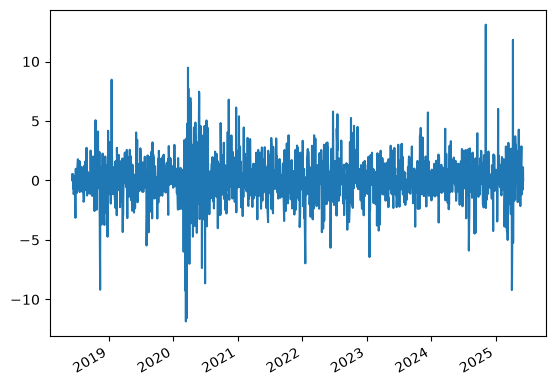

In [115]:
GS_r.plot()

In [105]:
test_estacionariedad_y_het(GS_r)

C:\Users\Markel\AppData\Local\Temp\ipykernel_19576\3844326302.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, adf_p, _, _, _, _ = adfuller(series, autolag='AIC')
C:\Users\Markel\AppData\Local\Temp\ipykernel_19576\3844326302.py:15: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_stat, kpss_p, _, _ = kpss(series, regression='c', nlags='auto')
C:\Users\Markel\AppData\Local\Temp\ipykernel_19576\3844326302.py:15: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lag

,Estadístico,p-value,Estacionariedad (0.05)
ADF,-40.299486,0.0,True
KPSS,0.102191,0.1,True
ARCH_Heteroskedasticity,202.798468,0.0,True


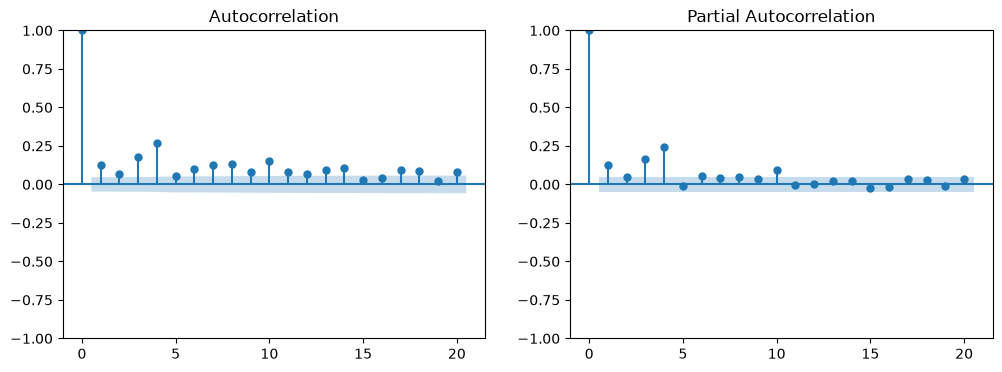

In [106]:
GS_sq = GS_r ** 2

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
tsaplots.plot_acf(GS_sq, lags=20, ax=ax[0])
tsaplots.plot_pacf(GS_sq, lags=20, ax=ax[1])
plt.show()

In [107]:
tabla_resumen = evaluate_volatility_models(GS_r, max_arch_p=4)
print(tabla_resumen.to_string(index=False))

c:\BDATA\BDATAIII\CasosPrácticosIII\26-27_3_R9_EQUIPO_MORADO\.venv\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


     Model  All Params Significant (<0.05)  ARCH-LM P-value  ARCH-LM Passed (>0.05)                                                                                Parameter P-values
   ARCH(1)                            True           0.0000                   False                                                       mu: 0.0185, omega: 0.0000, alpha[1]: 0.0016
   ARCH(2)                            True           0.0000                   False                                     mu: 0.0232, omega: 0.0000, alpha[1]: 0.0034, alpha[2]: 0.0479
   ARCH(3)                           False           0.0009                   False                   mu: 0.0079, omega: 0.0000, alpha[1]: 0.0021, alpha[2]: 0.1642, alpha[3]: 0.0025
   ARCH(4)                           False           0.9334                    True mu: 0.0135, omega: 0.0000, alpha[1]: 0.0062, alpha[2]: 0.1533, alpha[3]: 0.0108, alpha[4]: 0.0018
GARCH(1,1)                           False           0.4402                    True       

c:\BDATA\BDATAIII\CasosPrácticosIII\26-27_3_R9_EQUIPO_MORADO\.venv\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(
c:\BDATA\BDATAIII\CasosPrácticosIII\26-27_3_R9_EQUIPO_MORADO\.venv\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(
c:\BDATA\BDA

### KO (Coca Cola)

<Axes: >

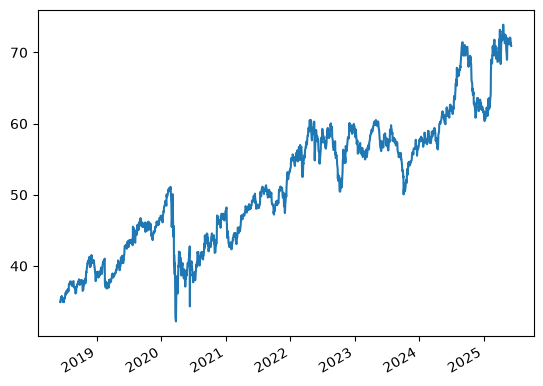

In [108]:
KO.plot()

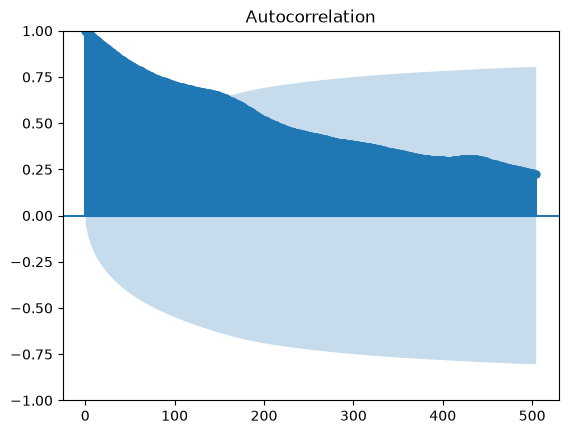

In [109]:
tsaplots.plot_acf(KO, lags=504);

Al no descubrir ninguna estacionalidad, quitaremos solamente la tendencia y observaremos la homocedasticidad. Al tratarse de una serie financiera, y al poder diferenciar la serie para restarle la tendencia; se decide trabajar sobre los retornos. Los retornos o rentabilidades son un resultado similar a la diferenciación, además de ser el estándar del sector para tratar las series temporales, no sobre los precios absolutos.

In [110]:
KO_r = KO.pct_change().dropna()*100

<Axes: >

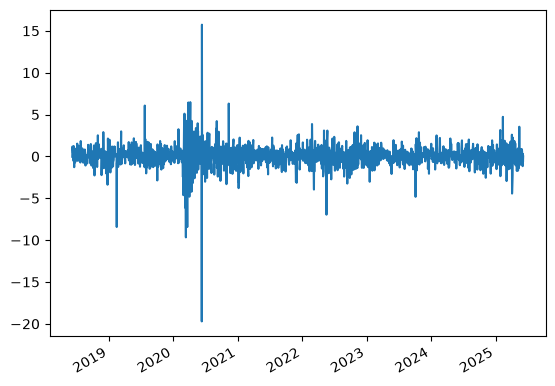

In [116]:
KO_r.plot()

In [111]:
test_estacionariedad_y_het(KO_r)

C:\Users\Markel\AppData\Local\Temp\ipykernel_19576\3844326302.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, adf_p, _, _, _, _ = adfuller(series, autolag='AIC')
C:\Users\Markel\AppData\Local\Temp\ipykernel_19576\3844326302.py:15: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_stat, kpss_p, _, _ = kpss(series, regression='c', nlags='auto')
C:\Users\Markel\AppData\Local\Temp\ipykernel_19576\3844326302.py:15: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lag

,Estadístico,p-value,Estacionariedad (0.05)
ADF,-9.945962,0.0,True
KPSS,0.024079,0.1,True
ARCH_Heteroskedasticity,368.344744,0.0,True


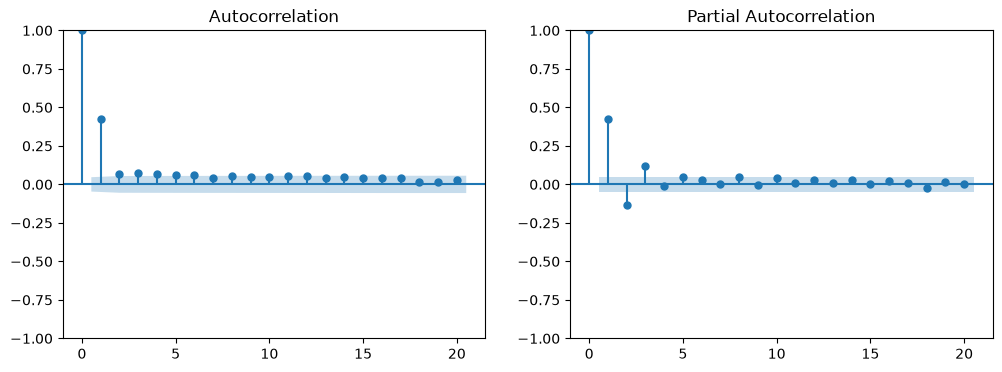

In [112]:
KO_sq = KO_r ** 2

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
tsaplots.plot_acf(KO_sq, lags=20, ax=ax[0])
tsaplots.plot_pacf(KO_sq, lags=20, ax=ax[1])
plt.show()

In [113]:
tabla_resumen = evaluate_volatility_models(KO_r, max_arch_p=3)
print(tabla_resumen.to_string(index=False))

c:\BDATA\BDATAIII\CasosPrácticosIII\26-27_3_R9_EQUIPO_MORADO\.venv\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(
c:\BDATA\BDATAIII\CasosPrácticosIII\26-27_3_R9_EQUIPO_MORADO\.venv\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


     Model  All Params Significant (<0.05)  ARCH-LM P-value  ARCH-LM Passed (>0.05)                                                                              Parameter P-values
   ARCH(1)                           False           0.6294                    True                                                     mu: 0.4837, omega: 0.0000, alpha[1]: 0.0469
   ARCH(2)                           False           0.9345                    True                                   mu: 0.1625, omega: 0.0000, alpha[1]: 0.0006, alpha[2]: 0.0503
   ARCH(3)                           False           0.9776                    True                 mu: 0.2667, omega: 0.0000, alpha[1]: 0.0029, alpha[2]: 0.1034, alpha[3]: 0.0966
GARCH(1,1)                           False           0.4137                    True                                    mu: 0.0352, omega: 0.2723, alpha[1]: 0.0000, beta[1]: 0.0000
GARCH(1,2)                           False           0.6294                    True                 

c:\BDATA\BDATAIII\CasosPrácticosIII\26-27_3_R9_EQUIPO_MORADO\.venv\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(
c:\BDATA\BDATAIII\CasosPrácticosIII\26-27_3_R9_EQUIPO_MORADO\.venv\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(
c:\BDATA\BDA